
C:\scripts\conectar-colab.ps1 -Hostname "el-hostname-nuevo"
> Añadir blockquote



In [1]:
# ============================================
# SETUP COMPLETO: SSH + Cloudflare Tunnel para VS Code
# ============================================

PASSWORD = "Madrid110526!"

# 1. Instalar SSH server y generar claves de host
!apt-get update -qq
!apt-get install -y openssh-server > /dev/null 2>&1
!ssh-keygen -A

# 2. Forzar que sshd escuche en el puerto 22
!sed -i '/^Port /d' /etc/ssh/sshd_config
!echo "Port 22" >> /etc/ssh/sshd_config

# 3. Habilitar autenticación por password y login de root
!sed -i '/^PasswordAuthentication/d' /etc/ssh/sshd_config
!echo "PasswordAuthentication yes" >> /etc/ssh/sshd_config
!sed -i '/^PermitRootLogin/d' /etc/ssh/sshd_config
!echo "PermitRootLogin yes" >> /etc/ssh/sshd_config

# 4. Matar cualquier sshd anterior y arrancar limpio
!pkill sshd 2>/dev/null
import time
time.sleep(2)
!service ssh start
!service ssh status

# 5. Verificar que quedó escuchando en el puerto 22
!ss -tlnp | grep :22

# 6. Configurar contraseña de root
!echo "root:{}" .format(PASSWORD)
import subprocess
subprocess.run(f'echo "root:{PASSWORD}" | chpasswd', shell=True)

# 7. Instalar colab_ssh y lanzar el túnel
!pip install colab-ssh --upgrade -q
from colab_ssh import launch_ssh_cloudflared
launch_ssh_cloudflared(password=PASSWORD)

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
ssh-keygen: generating new host keys: RSA DSA ECDSA ED25519 
 * Starting OpenBSD Secure Shell server sshd
   ...done.
 * sshd is running
LISTEN 0      128        127.0.0.1:22         0.0.0.0:*    users:(("sshd",pid=1911,fd=3))         
/bin/bash: -c: line 1: syntax error near unexpected token `('
/bin/bash: -c: line 1: `echo "root:{}" .format(PASSWORD)'


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Importación de librerías esenciales.
import pandas as pd
import os
import xgboost as xgb
from datetime import timedelta

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Instalar XGBoost si no está ya instalado
!pip install xgboost

In [ ]:
# Placeholder para imports consolidados.
pass

In [ ]:
# Cambiar directorio y cargar datos.
os.chdir('/content/drive/MyDrive/Master/TFM/Datos')
df = pd.read_csv('BBDD_Hotel_Reservas_2023_2025.csv')
df.head()

,ReservaID,ClienteID,FechaReserva,CheckIn,CheckOut,Noches,Habitacion,Tipo,Canal,Pais,Adultos,Ninos,ADR,Importe,Estado
0,1904,830,2022-11-06,2023-01-01,2023-01-07,6,23,Suite,Expedia,Francia,1,1,124,744,Confirmada
1,946,1856,2022-12-27,2023-01-01,2023-01-03,2,6,Suite,Booking,Reino Unido,1,0,62,124,Confirmada
2,348,873,2022-10-19,2023-01-01,2023-01-02,1,23,Doble,Expedia,Francia,2,0,139,139,Confirmada
3,3960,510,2023-01-01,2023-01-01,2023-01-07,6,16,Individual,Web,Reino Unido,2,0,148,888,Confirmada
4,1074,1031,2022-09-03,2023-01-01,2023-01-04,3,7,Suite,Booking,Italia,1,2,143,429,Confirmada


### Información General del DataFrame

In [ ]:
# Resumen del DataFrame: tipos de datos, valores no nulos y uso de memoria.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13980 entries, 0 to 13979
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   ReservaID     13980 non-null  int64 
 1   ClienteID     13980 non-null  int64 
 2   FechaReserva  13980 non-null  object
 3   CheckIn       13980 non-null  object
 4   CheckOut      13980 non-null  object
 5   Noches        13980 non-null  int64 
 6   Habitacion    13980 non-null  int64 
 7   Tipo          13980 non-null  object
 8   Canal         13980 non-null  object
 9   Pais          13980 non-null  object
 10  Adultos       13980 non-null  int64 
 11  Ninos         13980 non-null  int64 
 12  ADR           13980 non-null  int64 
 13  Importe       13980 non-null  int64 
 14  Estado        13980 non-null  object
dtypes: int64(8), object(7)
memory usage: 1.6+ MB


### Estadísticas Descriptivas para Columnas Numéricas

In [ ]:
# estadísticas descriptivas para las columnas numéricas del DataFrame (media, desviación estándar, etc.).
display(df.describe())

,ReservaID,ClienteID,Noches,Habitacion,Adultos,Ninos,ADR,Importe
count,13980.000000,13980.000000,13980.000000,13980.000000,13980.000000,13980.000000,13980.000000,13980.000000
mean,6990.500000,1000.126323,3.979256,12.910730,1.497568,0.803290,114.746781,456.142847
std,4035.822717,572.895758,2.003502,7.157955,0.500012,0.803858,34.027780,274.682007
min,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,50.000000,51.000000
25%,3495.750000,509.000000,2.000000,7.000000,1.000000,0.000000,85.000000,234.000000
50%,6990.500000,997.000000,4.000000,13.000000,1.000000,1.000000,114.000000,414.000000
75%,10485.250000,1485.000000,6.000000,19.000000,2.000000,1.000000,144.000000,637.000000
max,13980.000000,2000.000000,7.000000,25.000000,2.000000,2.000000,182.000000,1267.000000


### Métricas para Variables Categóricas

In [ ]:
# Análisis de variables categóricas.
print("Análisis de variables categóricas:")
for column in df.select_dtypes(include='object').columns:
    print(f"\nColumna: {column}")
    print(f"Número de valores únicos: {df[column].nunique()}")
    print("Conteo de valores:")
    display(df[column].value_counts())

Análisis de variables categóricas:

Columna: FechaReserva
Número de valores únicos: 1184
Conteo de valores:


,count
FechaReserva,
2024-06-05,30
2024-05-18,30
2024-08-17,27
2025-04-11,26
2023-11-15,24
...,...
2022-10-11,1
2022-09-29,1
2022-10-02,1



Columna: CheckIn
Número de valores únicos: 1090
Conteo de valores:


,count
CheckIn,
2025-12-31,863
2024-12-04,30
2024-06-20,28
2024-07-27,28
2024-08-17,26
...,...
2025-01-15,1
2025-02-11,1
2025-01-19,1



Columna: CheckOut
Número de valores únicos: 1096
Conteo de valores:


...

,count
Canal,
Walk-in,2503
Agencia,2359
Teléfono,2338
Booking,2306
Web,2291
Expedia,2183



Columna: Pais
Número de valores únicos: 7
Conteo de valores:


,count
Pais,
Reino Unido,2031
Francia,2013
Alemania,2012
Portugal,2012
Italia,1996
España,1982
EEUU,1934



Columna: Estado
Número de valores únicos: 3
Conteo de valores:


,count
Estado,
Confirmada,13300
Cancelada,363
No Show,317


### Porcentaje de 'No Show' y 'Cancelada' por País y Canal

In [ ]:
# Calcular porcentaje de 'No Show' y 'Cancelada' por país y canal.
total_reservations = df.groupby(['Pais', 'Canal']).size().reset_index(name='TotalReservas')
filtered_df = df[df['Estado'].isin(['No Show', 'Cancelada'])]
status_counts = filtered_df.groupby(['Pais', 'Canal', 'Estado']).size().reset_index(name='ConteoEstado')
merged_df = pd.merge(status_counts, total_reservations, on=['Pais', 'Canal'], how='left')
merged_df['Porcentaje'] = (merged_df['ConteoEstado'] / merged_df['TotalReservas']) * 100
print("Porcentaje de 'No Show' y 'Cancelada' por País y Canal:")
display(merged_df.round(2))

Porcentaje de 'No Show' y 'Cancelada' por País y Canal:


,Pais,Canal,Estado,ConteoEstado,TotalReservas,Porcentaje
0,Alemania,Agencia,Cancelada,14,346,4.05
1,Alemania,Agencia,No Show,6,346,1.73
2,Alemania,Booking,Cancelada,5,306,1.63
3,Alemania,Booking,No Show,9,306,2.94
4,Alemania,Expedia,Cancelada,11,308,3.57
...,...,...,...,...,...,...
79,Reino Unido,Teléfono,No Show,13,341,3.81
80,Reino Unido,Walk-in,Cancelada,10,363,2.75
81,Reino Unido,Walk-in,No Show,6,363,1.65
82,Reino Unido,Web,Cancelada,7,332,2.11


## Creación de Nuevas Características Temporales

In [ ]:
# Crear nuevas características temporales a partir de las fechas.
df['FechaReserva'] = pd.to_datetime(df['FechaReserva'])
df['CheckIn'] = pd.to_datetime(df['CheckIn'])
df['CheckOut'] = pd.to_datetime(df['CheckOut'])
df['mes'] = df['FechaReserva'].dt.month
df['dia'] = df['FechaReserva'].dt.day
df['dia_de_la_semana'] = df['FechaReserva'].dt.dayofweek
display(df[['FechaReserva', 'mes', 'dia', 'dia_de_la_semana']].head())

,FechaReserva,mes,dia,dia_de_la_semana
0,2022-11-06,11,6,6
1,2022-12-27,12,27,1
2,2022-10-19,10,19,2
3,2023-01-01,1,1,6
4,2022-09-03,9,3,5


In [ ]:
# Definir fechas festivas para 2025 y 2026 y crear columna 'festivo_no_festivo'.
# Se añaden festivos comunes de 2026 para el pronóstico.
festivos_all_years = [
    pd.Timestamp('2025-01-01'), pd.Timestamp('2025-01-06'),
    pd.Timestamp('2025-04-18'), pd.Timestamp('2025-05-01'),
    pd.Timestamp('2026-01-01'), pd.Timestamp('2026-01-06'), # Festivos de 2026
    pd.Timestamp('2026-04-03'), pd.Timestamp('2026-05-01') # Festivos de 2026
]
festivos_set = set(festivos_all_years)
df['festivo'] = df['FechaReserva'].isin(festivos_set)
df['festivo_no_festivo'] = df['festivo'].apply(lambda x: 'Festivo' if x else 'No Festivo')
display(df[['FechaReserva', 'festivo_no_festivo']].head())

,FechaReserva,festivo_no_festivo
0,2022-11-06,No Festivo
1,2022-12-27,No Festivo
2,2022-10-19,No Festivo
3,2023-01-01,No Festivo
4,2022-09-03,No Festivo


## Evolutivo de Reservas Totales, % Cancelación y % No Show por Fecha

In [ ]:
# Agrupar por FechaReserva para calcular métricas diarias de reservas y añadir 'es_festivo'.
reservas_diarias = df.groupby('FechaReserva').agg(
    demanda=('ReservaID', 'count'),
    Canceladas=('Estado', lambda x: (x == 'Cancelada').sum()),
    NoShow=('Estado', lambda x: (x == 'No Show').sum()),
    demanda_noches=('Noches', 'sum'),
    demanda_habitaciones=('Habitacion', 'nunique'),
    es_festivo=('festivo', 'max') # True si algún día en el grupo es festivo
).reset_index()
reservas_diarias['PorcentajeCancelacion'] = (reservas_diarias['Canceladas'] / reservas_diarias['demanda']) * 100
reservas_diarias['PorcentajeNoShow'] = (reservas_diarias['NoShow'] / reservas_diarias['demanda']) * 100
reservas_diarias = reservas_diarias.sort_values(by='FechaReserva')
display(reservas_diarias.head())

,FechaReserva,demanda,Canceladas,NoShow,demanda_noches,demanda_habitaciones,es_festivo,PorcentajeCancelacion,PorcentajeNoShow
0,2022-09-03,1,0,0,3,1,False,0.0,0.0
1,2022-09-17,1,0,0,2,1,False,0.0,0.0
2,2022-09-18,1,0,0,1,1,False,0.0,0.0
3,2022-09-23,2,0,0,10,2,False,0.0,0.0
4,2022-09-24,1,0,0,2,1,False,0.0,0.0


### Visualización de Tendencias

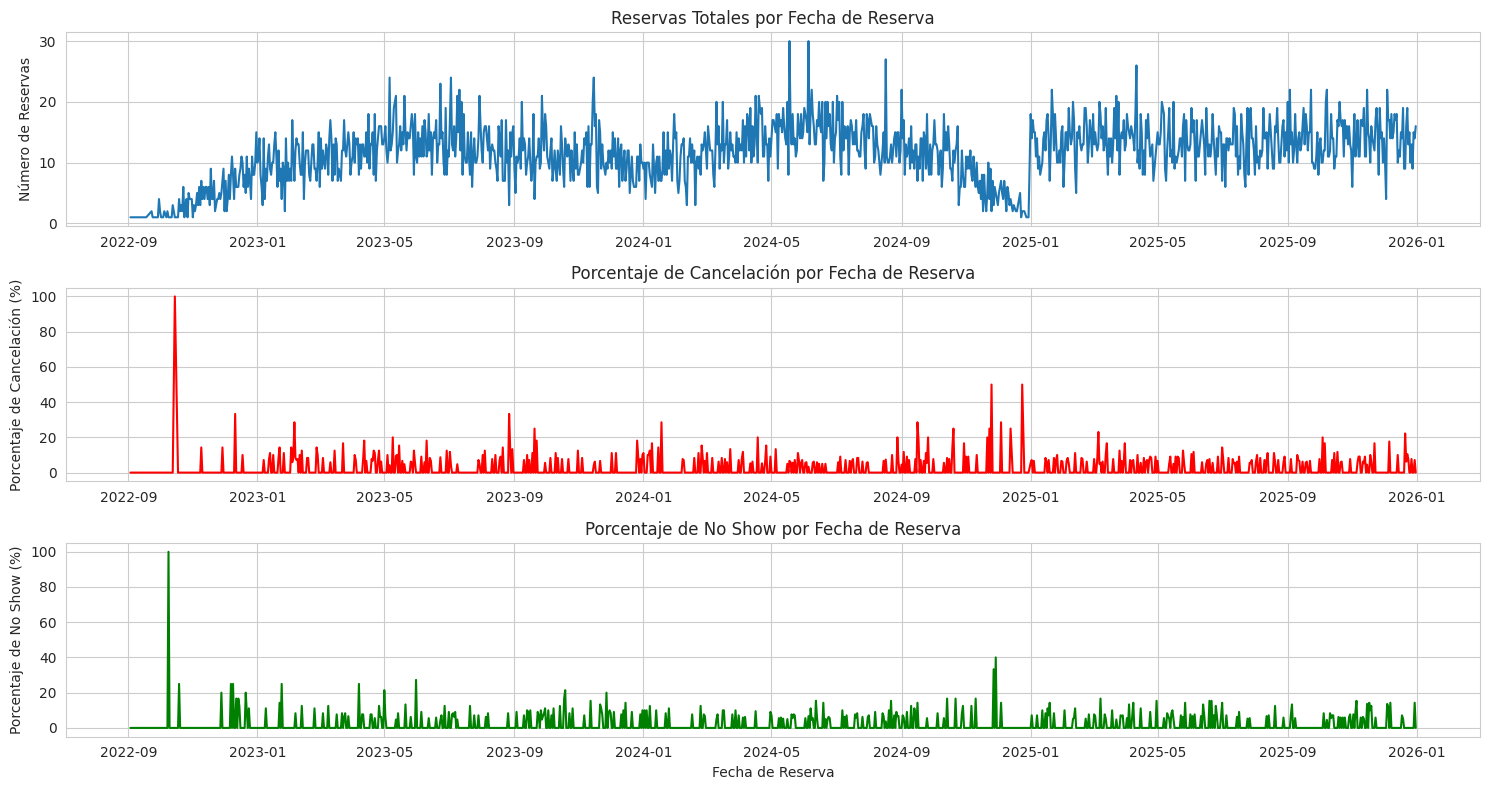

In [ ]:
# Visualizar tendencias de reservas, cancelación y no-show.
sns.set_style('whitegrid')
plt.figure(figsize=(15, 8))
plt.subplot(3, 1, 1)
sns.lineplot(x='FechaReserva', y='demanda', data=reservas_diarias)
plt.title('Reservas Totales por Fecha de Reserva')
plt.ylabel('Número de Reservas')
plt.xlabel('')
plt.subplot(3, 1, 2)
sns.lineplot(x='FechaReserva', y='PorcentajeCancelacion', data=reservas_diarias, color='red')
plt.title('Porcentaje de Cancelación por Fecha de Reserva')
plt.ylabel('Porcentaje de Cancelación (%)')
plt.xlabel('')
plt.subplot(3, 1, 3)
sns.lineplot(x='FechaReserva', y='PorcentajeNoShow', data=reservas_diarias, color='green')
plt.title('Porcentaje de No Show por Fecha de Reserva')
plt.ylabel('Porcentaje de No Show (%)')
plt.xlabel('Fecha de Reserva')
plt.tight_layout()
plt.show()

## Pronóstico de Series Temporales (Refactorizado)

### Variables Iniciales y Preparación

In [ ]:
# Inicializar variables y preparar 'reservas_diarias' para el pronóstico.
reservas_diarias['FechaReserva'] = pd.to_datetime(reservas_diarias['FechaReserva'])
fecha_inicio = reservas_diarias['FechaReserva'].min()
fecha_fin = reservas_diarias['FechaReserva'].max()
resultados_pronostico = []
print(f"Rango de fechas para el pronóstico usando reservas_diarias: {fecha_inicio.date()} a {fecha_fin.date()}")

Rango de fechas para el pronóstico usando reservas_diarias: 2022-09-03 a 2025-12-31


### Lógica de Backtesting y Entrenamiento del Modelo XGBoost

,fecha_pronostico,prediccion
0,2022-10-04,2.014218
1,2022-10-05,1.000321
2,2022-10-06,1.999417
3,2022-10-07,2.082122
4,2022-10-08,1.042454


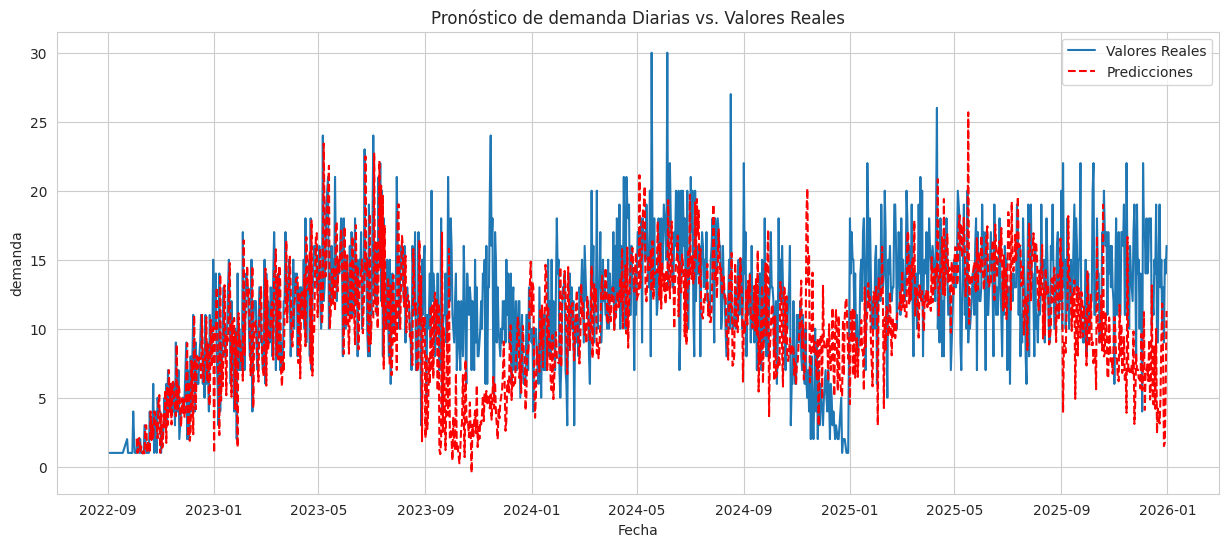

In [ ]:
# Preparar datos, entrenar modelo XGBoost y visualizar pronósticos, incluyendo 'es_festivo'.
reservas_diarias['mes'] = reservas_diarias['FechaReserva'].dt.month
reservas_diarias['dia_semana'] = reservas_diarias['FechaReserva'].dt.dayofweek
reservas_diarias['dia_anio'] = reservas_diarias['FechaReserva'].dt.dayofyear

target_variable_name = "demanda" # @param ["demanda","demanda_noches","demanda_habitaciones"]

# Extender el horizonte de predicción 15 días después de la última fecha histórica
fecha_fin_prediccion = fecha_fin + timedelta(days=15)

fecha_corte = fecha_inicio + timedelta(days=30)
resultados_pronostico = []

while fecha_corte <= fecha_fin_prediccion:
    # Para el entrenamiento, siempre usamos datos históricos hasta la fecha de corte actual
    train_data = reservas_diarias[reservas_diarias['FechaReserva'] <= fecha_corte].copy()
    target_column = target_variable_name
    features = ['mes', 'dia_semana', 'dia_anio', 'es_festivo'] # Se añade 'es_festivo'

    if len(train_data) > 1:
        X_train = train_data[features]
        y_train = train_data[target_column]
        model = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42)
        model.fit(X_train, y_train)

        if not X_train.empty:
            next_day_date = fecha_corte + timedelta(days=1)
            if next_day_date <= fecha_fin_prediccion:
                # Calcular 'es_festivo' para el día siguiente usando festivos_set actualizado
                es_festivo_next_day = next_day_date in festivos_set

                next_day_features = pd.DataFrame({
                    'mes': [next_day_date.month],
                    'dia_semana': [next_day_date.dayofweek],
                    'dia_anio': [next_day_date.dayofyear],
                    'es_festivo': [es_festivo_next_day]
                })
                pred = model.predict(next_day_features)
                resultados_pronostico.append({'fecha_pronostico': next_day_date, 'prediccion': pred[0]})
    fecha_corte += timedelta(days=1)

resultados_df_pronostico = pd.DataFrame(resultados_pronostico)
display(resultados_df_pronostico.head())

plt.figure(figsize=(15, 6))
sns.lineplot(x='FechaReserva', y=target_column, data=reservas_diarias, label='Valores Reales')
sns.lineplot(x='fecha_pronostico', y='prediccion', data=resultados_df_pronostico, label='Predicciones', color='red', linestyle='--')
plt.title(f'Pronóstico de {target_column} Diarias vs. Valores Reales (incluyendo los próximos 15 días de 2026)')
plt.xlabel('Fecha')
plt.ylabel(target_column)
plt.legend()
plt.show()

### Importancia de las Características del Modelo XGBoost

Importancia de las Características:


,Feature,Importance
2,dia_anio,0.369636
0,mes,0.347831
1,dia_semana,0.232582
3,es_festivo,0.049951


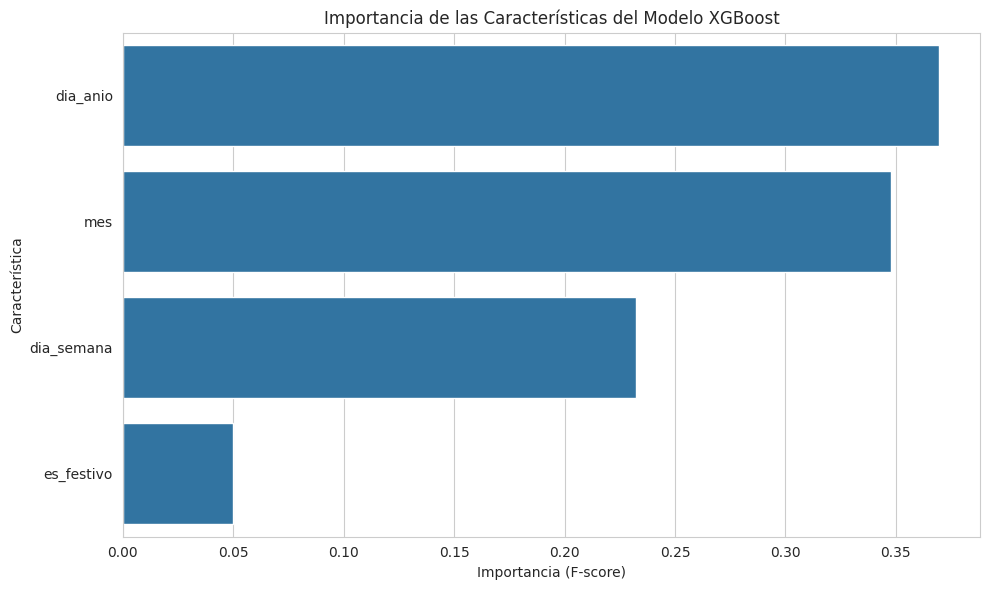

In [ ]:
# Calcular y mostrar la importancia de las características del modelo.
import matplotlib.pyplot as plt
import seaborn as sns

if 'model' in locals():
    feature_importances = model.feature_importances_
    feature_names = features

    # Crear un DataFrame para una mejor visualización
    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': feature_importances
    })

    # Ordenar por importancia de forma descendente
    importance_df = importance_df.sort_values(by='Importance', ascending=False)

    print("Importancia de las Características:")
    display(importance_df)

    # Visualizar la importancia de las características
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Importance', y='Feature', data=importance_df)
    plt.title('Importancia de las Características del Modelo XGBoost')
    plt.xlabel('Importancia (F-score)')
    plt.ylabel('Característica')
    plt.tight_layout()
    plt.show()
else:
    print("El modelo XGBoost no ha sido entrenado. Por favor, ejecuta la celda anterior para entrenar el modelo.")